# 02 Základní modely: ridge regrese a síť s maskou na více výstupů

**Otázka.** Jak přesně z 24 magnetických měření zrekonstruujeme 16 parametrů tvaru podle referenční rekonstrukce ústavu (poloha magnetické osy, dolního X bodu, dvou dotykových bodů a bodu limiteru, elongace, tři triangularity, proud plazmatu a příznak limiterové konfigurace) na náhodně vybraných celých výbojích, na kterých se model neučil, a kolik neuronová síť získá proti lineárnímu modelu? Obrys plazmatu se neodhaduje. Výsledky tu platí pro základní síť; model, který nasazujeme, se hodnotí v notebooku 09.

Protokol (platí pro celý projekt): 5násobný GroupKFold po výbojích, ztráta s maskou tam, kde cíl neexistuje, chyby ve fyzikálních
jednotkách (mm, kA) a vzhledem k rozptylu cíle (nRMSE = RMSE / směrodatná odchylka).
Síť je společná `common.fit_mlp` (256-256-128, SiLU, AdamW, plán one-cycle, 60 epoch), lineární
model je `ridge` s alpha 1. Oba se tu učí.

Doba běhu: asi 1 minuta (změřeno 41 s, 2 vlákna CPU); stačí surová data (`equil_data.csv`); volitelně `out/baseline.json` pro srovnání v oddílu 2 (`analysis/baseline_models.py`, 1 min).

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data: HACKATHON_HOME, jinak samotný repozitář, pokud má složku data/, jinak nadřazená složka repozitáře.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "common.py").exists()), None)
if repo is None:
    raise SystemExit("Spusťte z vnitřku repozitáře")
os.environ.setdefault("HACKATHON_HOME", str(repo if (repo / "data").is_dir() else repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("složka se surovými daty nalezena:", C.DATA.exists(), "| složka s výsledky nalezena:", C.OUT.exists())

složka se surovými daty nalezena: True | složka s výsledky nalezena: True


## 1. Foldy

In [2]:
df, X, Y, G, M = C.load()
J = {t: i for i, t in enumerate(C.TARGETS)}
folds = C.group_folds(X, Y, G, 5)
lim = Y[:, J["is_limited"]] > 0.5
KEY = {}
rows = []
for k, (tr, te) in enumerate(folds):
    assert not set(G[tr]) & set(G[te]), "výboj je v učicí i testovací části"
    rows.append(dict(fold=k + 1, učicích_výbojů=len(set(G[tr])), testovacích_výbojů=len(set(G[te])), učicích_řádků=len(tr), testovacích_řádků=len(te), podíl_limiterových_v_testu=lim[te].mean()))
print(pd.DataFrame(rows).set_index("fold").round(3).to_string())
print("žádný výboj není zároveň v učicí a testovací části žádného foldu")

      učicích_výbojů  testovacích_výbojů  učicích_řádků  testovacích_řádků  podíl_limiterových_v_testu
fold                                                                                                  
1                119                  30          34381               8591                       0.430
2                119                  30          34398               8574                       0.415
3                120                  29          34415               8557                       0.496
4                119                  30          34311               8661                       0.423
5                119                  30          34383               8589                       0.448
žádný výboj není zároveň v učicí a testovací části žádného foldu


## 2. Učení ridge a sítě na každém foldu

Predikce mimo učicí sadu (každý řádek odhaduje model, který jeho výboj nikdy neviděl) zůstávají v paměti pro grafy
níže.

In [3]:
t0 = time.time()
ridge_res, mlp_res = [], []
P_ridge = np.full(Y.shape, np.nan, dtype=np.float32)
P_mlp = np.full(Y.shape, np.nan, dtype=np.float32)
fold_of = np.zeros(len(X), dtype=int)
for k, (tr, te) in enumerate(folds):
    ridge_pred = C.fit_ridge(X[tr], Y[tr], M[tr])(X[te])
    predict, net, _ = C.fit_mlp(X[tr], Y[tr], M[tr], epochs=60, seed=k)
    P_ridge[te], P_mlp[te], fold_of[te] = ridge_pred, predict(X[te]), k
    ridge_res.append(C.score(P_ridge[te], Y[te], M[te]))
    mlp_res.append(C.score(P_mlp[te], Y[te], M[te]))
    print(f"fold {k + 1}/5 hotov, {time.time() - t0:.0f} s", flush=True)
KEY["training_seconds_5_folds_both_models"] = round(time.time() - t0, 1)
KEY["network_parameters"] = int(sum(p.numel() for p in net.parameters()))


def mean_over_folds(res, t, key):
    return float(np.mean([f[t][key] for f in res]))


def std_over_folds(res, t, key):
    return float(np.std([f[t][key] for f in res]))

fold 1/5 hotov, 13 s


fold 2/5 hotov, 22 s


fold 3/5 hotov, 32 s


fold 4/5 hotov, 42 s


fold 5/5 hotov, 52 s


## 3. Tabulka výsledků (průměr přes 5 foldů)

`spread` je směrodatná odchylka cíle ve stejné jednotce; `MLP MAE / spread` říká, jak velká je typická chyba
vzhledem k tomu, jak moc se veličina pohybuje.

In [4]:
rows = []
for t in C.TARGETS:
    scale, unit = C.UNIT[t]
    j = J[t]
    spread = float(Y[M[:, j], j].std() * scale)
    rows.append(dict(cíl=t, jednotka=unit or "-", spread=spread,
                     ridge_MAE=mean_over_folds(ridge_res, t, "mae"), MLP_MAE=mean_over_folds(mlp_res, t, "mae"),
                     MLP_MAE_fold_std=std_over_folds(mlp_res, t, "mae"),
                     MLP_MAE_over_spread=mean_over_folds(mlp_res, t, "mae") / spread,
                     ridge_R2=mean_over_folds(ridge_res, t, "r2"), MLP_R2=mean_over_folds(mlp_res, t, "r2"),
                     ridge_nRMSE=mean_over_folds(ridge_res, t, "nrmse"), MLP_nRMSE=mean_over_folds(mlp_res, t, "nrmse")))
tab = pd.DataFrame(rows).set_index("cíl")
print(tab.round(4).to_string())
KEY["table"] = {t: {k: (round(float(v), 5) if k != "jednotka" else v) for k, v in r.items()} for t, r in tab.to_dict("index").items()}
KEY["is_limited_accuracy"] = {"ridge": mean_over_folds(ridge_res, "is_limited", "accuracy"), "mlp": mean_over_folds(mlp_res, "is_limited", "accuracy")}
print()
print(f"přesnost is_limited: ridge {KEY['is_limited_accuracy']['ridge']:.4f}, MLP {KEY['is_limited_accuracy']['mlp']:.4f}")
KEY["mean_nrmse_without_limiter_targets"] = {
    m: float(np.mean([mean_over_folds(res, t, "nrmse") for t in C.TARGETS if t not in ("R_limiter", "Z_limiter", "is_limited")]))
    for m, res in (("ridge", ridge_res), ("mlp", mlp_res))}
print("průměrné nRMSE přes 13 cílů bez bodu limiteru a is_limited:", {k: round(v, 4) for k, v in KEY["mean_nrmse_without_limiter_targets"].items()})

                    jednotka    spread  ridge_MAE  MLP_MAE  MLP_MAE_fold_std  MLP_MAE_over_spread  ridge_R2  MLP_R2  ridge_nRMSE  MLP_nRMSE
cíl                                                                                                                                        
plasma_current            kA  114.1844     0.0323   1.4884            0.4218               0.0130    1.0000  0.9992       0.0004     0.0271
R_mag_axis                mm    8.0216     2.4045   0.3773            0.1164               0.0470    0.5273  0.9766       0.6817     0.1394
Z_mag_axis                mm   13.7411     2.6627   0.3915            0.0787               0.0285    0.7739  0.9844       0.4450     0.1070
elongation                 -    0.2706     0.0921   0.0057            0.0013               0.0210    0.5961  0.9982       0.6251     0.0408
triangularity              -    0.1194     0.0411   0.0028            0.0006               0.0238    0.5740  0.9974       0.6441     0.0483
triangularity_upper 

### Souhlasí to s dřívějším skriptem?

`analysis/baseline_models.py` zapsal `out/baseline.json` se stejným protokolem (běžel na 4 vláknech torche). Malé
rozdíly jsou očekávané, protože učení není bit po bitu stejné při různém počtu vláken.

In [5]:
saved_path = C.OUT / "baseline.json"
if saved_path.exists():
    saved = json.load(open(saved_path))["average"]["mlp"]
    cmp = pd.DataFrame({"tento notebook": {t: tab.loc[t, "MLP_MAE"] for t in C.TARGETS}, "uložený skript": {t: saved[t]["mae"] for t in C.TARGETS}})
    cmp["ratio"] = cmp["tento notebook"] / cmp["uložený skript"]
    print(cmp.round(4).to_string())
    KEY["ratio_to_saved_baseline_min_max"] = [float(cmp.ratio.min()), float(cmp.ratio.max())]
else:
    print("uložený baseline nenalezen; srovnání se přeskočí")

                     tento notebook  uložený skript   ratio
plasma_current               1.4884          1.4879  1.0003
R_mag_axis                   0.3773          0.3772  1.0004
Z_mag_axis                   0.3915          0.3915  1.0000
elongation                   0.0057          0.0057  1.0005
triangularity                0.0028          0.0028  1.0006
triangularity_upper          0.0030          0.0030  0.9996
triangularity_lower          0.0037          0.0037  0.9998
R_x_point                    0.2025          0.2025  1.0002
Z_x_point                    0.1954          0.1953  1.0005
R_strike_point_1             0.2653          0.2648  1.0019
Z_strike_point_1             0.1307          0.1309  0.9989
R_strike_point_2             0.2279          0.2281  0.9991
Z_strike_point_2             0.0551          0.0552  0.9983
R_limiter                   10.7309         10.7304  1.0000
Z_limiter                   22.1943         22.1937  1.0000
is_limited                   0.0203     

## 4. Grafy: relativní chyba podle cíle a odhad proti referenci

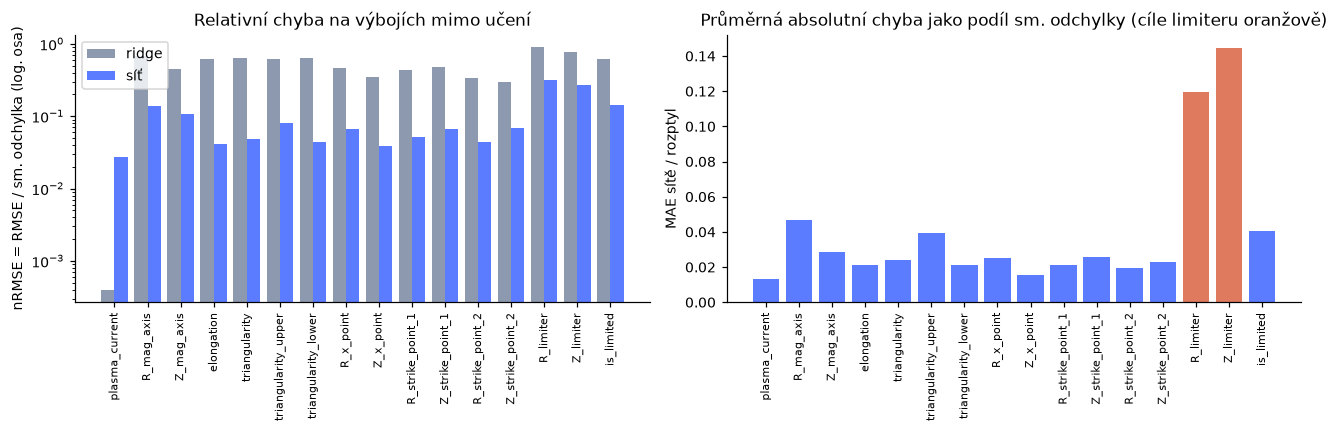

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xs = np.arange(len(C.TARGETS))
ax[0].bar(xs - 0.2, tab.ridge_nRMSE, 0.4, label="ridge", color="#8d99ae")
ax[0].bar(xs + 0.2, tab.MLP_nRMSE, 0.4, label="síť", color="#5b7cff")
ax[0].set_yscale("log"); ax[0].set_xticks(xs); ax[0].set_xticklabels(C.TARGETS, rotation=90, fontsize=7)
ax[0].set_ylabel("nRMSE = RMSE / sm. odchylka (log. osa)"); ax[0].legend(); ax[0].set_title("Relativní chyba na výbojích mimo učení")
ax[1].bar(xs, tab.MLP_MAE_over_spread, color=["#e07a5f" if t in ("R_limiter", "Z_limiter") else "#5b7cff" for t in C.TARGETS])
ax[1].set_xticks(xs); ax[1].set_xticklabels(C.TARGETS, rotation=90, fontsize=7)
ax[1].set_ylabel("MAE sítě / rozptyl"); ax[1].set_title("Průměrná absolutní chyba jako podíl sm. odchylky (cíle limiteru oranžově)")
fig.tight_layout(); plt.show()

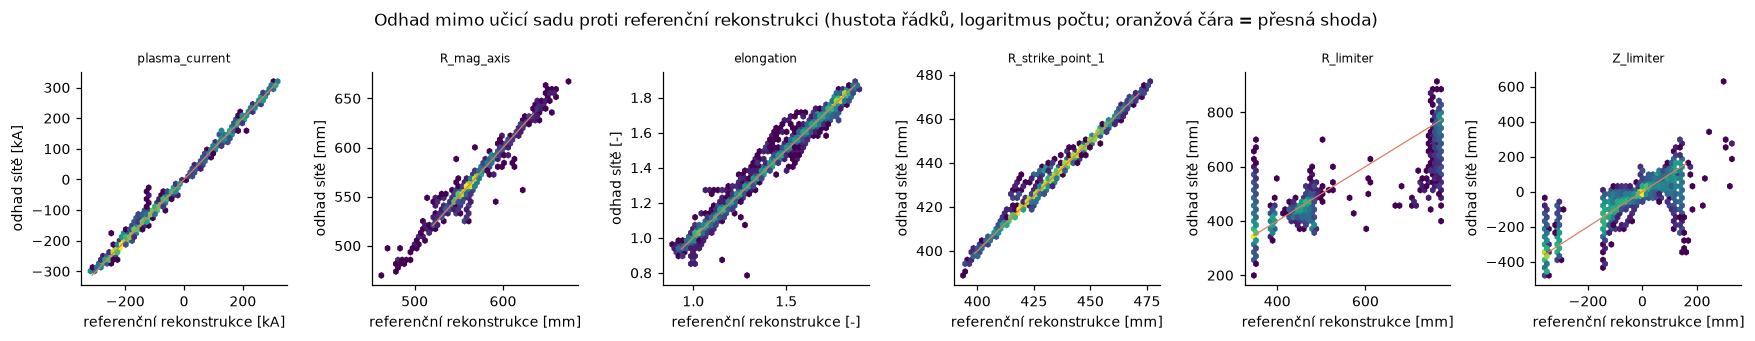

In [7]:
show = ["plasma_current", "R_mag_axis", "elongation", "R_strike_point_1", "R_limiter", "Z_limiter"]
fig, ax = plt.subplots(1, len(show), figsize=(16, 3.1))
for a, t in zip(ax, show):
    j = J[t]; scale, unit = C.UNIT[t]; k = M[:, j]
    a.hexbin(Y[k, j] * scale, P_mlp[k, j] * scale, gridsize=45, bins="log", cmap="viridis", mincnt=1)
    lo, hi = np.percentile(Y[k, j] * scale, [0.1, 99.9])
    a.plot([lo, hi], [lo, hi], color="#e07a5f", lw=0.8)
    a.set_title(t, fontsize=8); a.set_xlabel(f"referenční rekonstrukce [{unit or '-'}]"); a.set_ylabel(f"odhad sítě [{unit or '-'}]")
fig.suptitle("Odhad mimo učicí sadu proti referenční rekonstrukci (hustota řádků, logaritmus počtu; oranžová čára = přesná shoda)")
fig.tight_layout(); plt.show()

## 5. Kde je síť nejslabší: bod limiteru

`R_limiter` a `Z_limiter` existují jen tehdy, když se plazma dotýká limiteru. Podíváme se na ně podle konfigurace a podle toho,
jestli se správně určil samotný příznak `is_limited`.

is_limited určeno špatně v 0.0074 všech řádků mimo učicí sadu
               jednotka  MAE_limiterové_řádky  MAE_divertorové_řádky
cíl                                                                 
plasma_current       kA                2.0120                 1.0718
R_mag_axis           mm                0.5534                 0.2373
Z_mag_axis           mm                0.5157                 0.2928
elongation            -                0.0082                 0.0037
triangularity         -                0.0042                 0.0018
          jednotka   spread  MAE_vše  MAE_medián    MAE_p95  MAE_třída_správně  MAE_třída_špatně  řádků_špatná_třída
cíl                                                                                                                 
R_limiter       mm   89.597   10.807       2.639  48.953999             10.775         14.492000                 163
Z_limiter       mm  153.271   22.253       9.304  90.850998             22.289         17.981001        

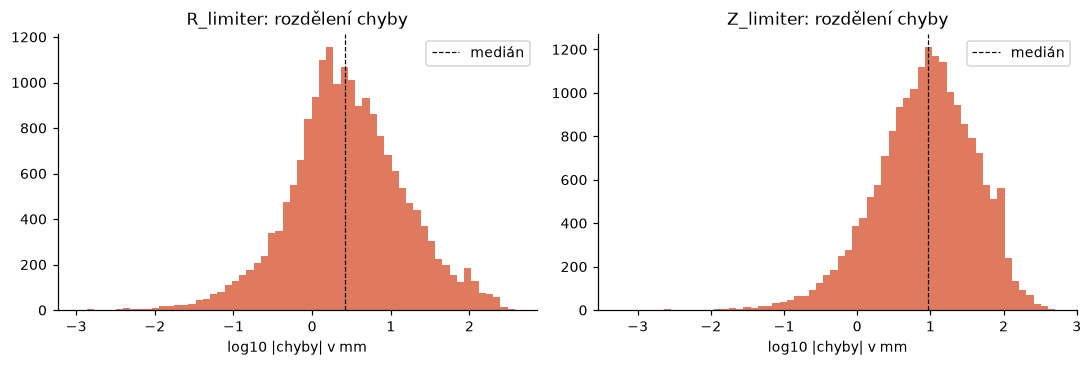

chvost chyby radiální a svislé osy (medián, 99. percentil; mm): {'R_mag_axis': [0.153, 3.74], 'Z_mag_axis': [0.18, 3.57]}


In [8]:
pooled = C.score(P_mlp, Y, M)
KEY["pooled_oof_mae"] = {t: round(pooled[t]["mae"], 5) for t in C.TARGETS}
pred_lim = P_mlp[:, J["is_limited"]] > 0.5
KEY["misclassified_share"] = float((pred_lim != lim).mean())
print(f"is_limited určeno špatně v {KEY['misclassified_share']:.4f} všech řádků mimo učicí sadu")
rows = []
for t in ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "triangularity"]:
    j = J[t]; scale, unit = C.UNIT[t]
    e = np.abs(P_mlp[:, j] - Y[:, j]) * scale
    rows.append(dict(cíl=t, jednotka=unit or "-", MAE_limiterové_řádky=np.nanmean(e[lim]), MAE_divertorové_řádky=np.nanmean(e[~lim])))
by_config = pd.DataFrame(rows).set_index("cíl")
print(by_config.round(4).to_string())
KEY["mae_by_configuration"] = {t: [round(float(r.MAE_limiterové_řádky), 5), round(float(r.MAE_divertorové_řádky), 5)] for t, r in by_config.iterrows()}

rows = []
for t in ("R_limiter", "Z_limiter"):
    j = J[t]; scale, unit = C.UNIT[t]
    k = M[:, j]
    e = np.abs(P_mlp[:, j] - Y[:, j]) * scale
    ok = k & pred_lim
    bad = k & ~pred_lim
    rows.append(dict(cíl=t, jednotka=unit, spread=float(Y[k, j].std() * scale), MAE_vše=e[k].mean(), MAE_medián=np.median(e[k]),
                     MAE_p95=np.percentile(e[k], 95), MAE_třída_správně=e[ok].mean(), MAE_třída_špatně=e[bad].mean() if bad.any() else np.nan,
                     řádků_špatná_třída=int(bad.sum())))
lt = pd.DataFrame(rows).set_index("cíl")
print(lt.round(3).to_string())
KEY["limiter"] = {t: {k: (round(float(v), 4)) for k, v in r.items() if k != "jednotka"} for t, r in lt.to_dict("index").items()}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, t in zip(ax, ("R_limiter", "Z_limiter")):
    j = J[t]; scale, unit = C.UNIT[t]; k = M[:, j]
    e = np.abs(P_mlp[k, j] - Y[k, j]) * scale
    a.hist(np.log10(e + 1e-6), bins=60, color="#e07a5f")
    a.axvline(np.log10(np.median(e)), color="k", lw=0.8, ls="--", label="medián")
    a.set_xlabel(f"log10 |chyby| v {unit}"); a.set_title(f"{t}: rozdělení chyby"); a.legend()
fig.tight_layout(); plt.show()
print("chvost chyby radiální a svislé osy (medián, 99. percentil; mm):", {t: [round(float(np.nanmedian(np.abs(P_mlp[:, J[t]] - Y[:, J[t]]) * C.UNIT[t][0])), 3), round(float(np.nanpercentile(np.abs(P_mlp[:, J[t]] - Y[:, J[t]]) * C.UNIT[t][0], 99)), 2)] for t in ("R_mag_axis", "Z_mag_axis")})

## 6. Nerovnoměrné rozdělení tvarů (REQ-007): je chyba větší u vzácných tvarů?

Rozsah elongace rozdělíme na 10 stejně širokých košů. Běžné tvary zaplní pár košů, vzácné tvary leží v řídkých.
Chyba na koš je MAE sítě mimo učicí sadu pro `elongation`, `R_mag_axis` a `plasma_current`.

     elongace_od  řádků  MAE_elongation  MAE_R_mag_axis  MAE_plasma_current
koš                                                                        
1         0.8865    259          0.0136          3.0486              2.2339
2         0.9872   3614          0.0064          0.8859              2.4208
3         1.0879   2150          0.0077          0.6698              1.9944
4         1.1887   1831          0.0061          0.5977              1.7881
5         1.2894   1670          0.0056          0.3243              1.4811
6         1.3901   1915          0.0078          0.2772              1.4064
7         1.4908   1346          0.0105          0.3550              1.8335
8         1.5915   2345          0.0115          0.4473              3.2651
9         1.6923  12704          0.0054          0.3178              1.2770
10        1.7930  15137          0.0037          0.2012              1.0259
elongation: MAE ve 3 nejplnějších koších 0.0047, v koších s méně než 2 % řádků 0.01361 (

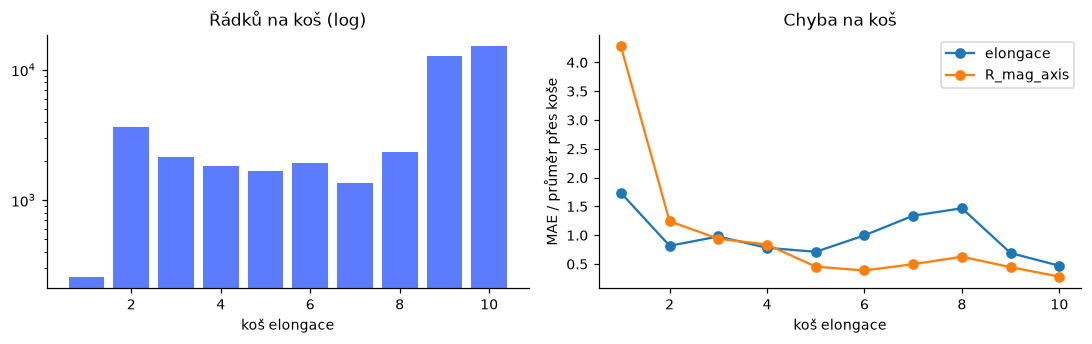

In [9]:
valid = M[:, [J["elongation"], J["R_mag_axis"], J["plasma_current"]]].all(1)  # jednomu řádku chybí několik cílů
el = Y[valid, J["elongation"]].astype(np.float64)
Pv, Yv = P_mlp[valid], Y[valid]
edges = np.linspace(el.min(), el.max() + 1e-9, 11)
b = np.clip(np.digitize(el, edges) - 1, 0, 9)
cnt = np.bincount(b, minlength=10)
rows = []
for i in range(10):
    s = b == i
    row = dict(koš=i + 1, elongace_od=edges[i], řádků=int(cnt[i]))
    for t in ("elongation", "R_mag_axis", "plasma_current"):
        j = J[t]; scale, unit = C.UNIT[t]
        row[f"MAE_{t}"] = np.abs(Pv[s, j] - Yv[s, j]).mean() * scale if s.sum() else np.nan
    rows.append(row)
dens = pd.DataFrame(rows).set_index("koš")
print(dens.round(4).to_string())
common = cnt >= np.sort(cnt)[-3]
sparse = (cnt > 0) & (cnt < 0.02 * len(el))
KEY["density_bins"] = {"rows_per_bin": cnt.tolist()}
for t in ("elongation", "R_mag_axis", "plasma_current"):
    j = J[t]; scale, unit = C.UNIT[t]
    e = np.abs(Pv[:, j] - Yv[:, j]) * scale
    in_common = common[b]
    in_sparse = sparse[b]
    KEY["density_bins"][t] = {"MAE_in_3_fullest_bins": float(e[in_common].mean()), "MAE_in_sparse_bins_under_2pct_of_rows": float(e[in_sparse].mean()) if in_sparse.any() else None,
                              "rows_in_sparse_bins": int(in_sparse.sum())}
    print(f"{t}: MAE ve 3 nejplnějších koších {e[in_common].mean():.4g}, v koších s méně než 2 % řádků {e[in_sparse].mean():.4g} ({in_sparse.sum()} řádků) [{unit or '-'}]")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(range(1, 11), cnt, color="#5b7cff"); ax[0].set_yscale("log"); ax[0].set_xlabel("koš elongace"); ax[0].set_title("Řádků na koš (log)")
ax[1].plot(range(1, 11), dens.MAE_elongation / dens.MAE_elongation.mean(), marker="o", label="elongace")
ax[1].plot(range(1, 11), dens.MAE_R_mag_axis / dens.MAE_R_mag_axis.mean(), marker="o", label="R_mag_axis")
ax[1].set_xlabel("koš elongace"); ax[1].set_ylabel("MAE / průměr přes koše"); ax[1].legend(); ax[1].set_title("Chyba na koš")
fig.tight_layout(); plt.show()

## Závěry

- **Nastavení.** 5 foldů po celých výbojích (v každém asi 119 až 120 učicích a 29 až 30 testovacích výbojů, ověřeno: žádný výboj není na obou stranách), ztráta s maskou, síť se 107 152 parametry, 60 epoch. Učení obou modelů na všech foldech trvalo v uloženém běhu 35 s na 2 vláknech (172 s při prvním běhu na vytíženém stroji). Výsledky se shodují s dřívějším skriptem `baseline_models.py` (poměr hodnot MAE od 1,0000 do 1,0000 na stroji autora se stejným počtem vláken; jiný procesor dá malé rozdíly a bez `out/baseline.json` se toto srovnání přeskočí).
- **Síť se s referenční rekonstrukcí shoduje velmi dobře i na výbojích, na kterých se neučila** (náhodné skupinové foldy; štítky jsou rekonstrukce ústavu, ne nezávislé měření plazmatu). Průměrný absolutní rozdíl: `R_mag_axis` 0,38 mm, `Z_mag_axis` 0,39 mm, `R_x_point` 0,20 mm, `R_strike_point_1` 0,26 mm, `R_strike_point_2` 0,23 mm, elongace 0,0057, proud plazmatu 1,49 kA. `is_limited` se shoduje v 99,26 % řádků. Průměrná absolutní chyba je 1,3 % až 4,7 % směrodatné odchylky každého cíle (bez bodu limiteru); nRMSE, které víc váží velké chyby, je 2,7 % až 13,9 %. Průměr skrývá chvost: u `R_mag_axis` je medián 0,15 mm, 99 % řádků je pod 3,7 mm a nejhorší řádek má 64 mm (`results/distribution.md`), většinou na obou koncích výboje. Čísla výbojů zřejmě sledují čas (organizátoři nepotvrdili); při učení na 60 nejnižších a testu na 59 nejvyšších vývojových výbojích je chyba radiální osy 1,23 mm místo 0,45 mm na týchž výbojích (`results/final-evaluation.md`; část z toho dělá menší učicí sada; viz notebook 09).
- **Síť porazí ridge téměř ve všem.** Průměrné nRMSE přes 13 cílů bez bodu limiteru a `is_limited` je 0,0633 pro síť a 0,4629 pro ridge (7,3krát horší) a přesnost `is_limited` je u ridge 91,2 %. Například `R_mag_axis` má u ridge MAE 2,40 mm proti 0,38 mm.
- **Jedna výjimka: proud plazmatu je v měřeních lineární.** Ridge dosáhne u proudu plazmatu MAE 0,035 kA (R na druhou 1,0000), zatímco síť má 1,49 kA, tedy asi 43krát hůř. Pro tento jediný výstup má smysl použít lineární model (samotný, nebo jako vstup sítě). Dá se to čekat z Ampérova zákona: 16 cívek IPR integruje magnetické pole kolem komory. Shoda 0,035 kA na rozptylu 114 kA (0,03 %) naznačuje, že referenční proud byl odvozen ze stejných signálů a neměřil se nezávisle (náš závěr, nepotvrzený).
- **Bod limiteru je slabé místo.** `R_limiter` má MAE 10,7 mm (12 % rozptylu 90 mm) a `Z_limiter` 22,2 mm (14 % z 153 mm). Chyba má těžký chvost: medián chyby `R_limiter` je 2,6 mm, ale 95. percentil 49 mm. Špatné určení `is_limited` (0,74 % řádků, 163 řádků s bodem limiteru) hlavní příčina není: přes všechny řádky mimo učicí sadu je MAE `R_limiter` 10,8 mm při správné třídě a 14,5 mm při špatné. U `Z_limiter` špatná třída horší není (18,0 proti 22,3 mm).
- **Limiterové plazma je těžší než divertorové.** MAE `R_mag_axis` je 0,55 mm v limiterových řádcích a 0,24 mm v divertorových; u proudu plazmatu 2,01 a 1,07 kA; u elongace 0,0082 a 0,0037.
- **Vzácné tvary mají větší chyby (REQ-007).** Ve 3 nejplnějších koších elongace je MAE `R_mag_axis` 0,33 mm; v řídkých koších (pod 2 % řádků, 259 řádků, nejméně protažená plazmata) je 3,05 mm a u samotné elongace 0,0047 proti 0,0136. Hlavní průměry určují běžné tvary. Limiterové plazma nese 91,9 % čtverce chyby `R_mag_axis` při 44,2 % řádků, 16 výbojů s kladným znaménkem proudu 77,8 % při 7,4 % řádků a poslední 2 % výboje 26,9 % při 2,2 % řádků (notebook 07). Změřeno, ne opraveno: nezkoušelo se převažování ani stratifikované foldy. Nejřidší koš elongace obsahuje hodnoty pod 1 (0,89 až 0,99), které jsou pro tokamakové plazma neobvyklé; definici organizátorů tu nemáme zaznamenanou.
- **Výhrada.** Jedno semínko na fold; směrodatná odchylka přes foldy je v tabulce výsledků (například `R_mag_axis` 0,38 plus mínus 0,12 mm).

*Závěry výše jsem opsal z výstupů uloženého běhu; po novém spuštění se mírně liší.*

**Odpověď.** Na náhodně vybraných výbojích, na kterých se model neučil, se síť liší od referenční rekonstrukce ústavu v poloze osy průměrně o 0,38 mm (radiálně) a 0,39 mm (svisle) (medián 0,15 mm, 99 % řádků pod 3,7 mm) a v souhrnné chybě je 7,3krát lepší než ridge; jen u proudu plazmatu je lepší lineární model (0,035 proti 1,49 kA). Slabým místem je bod limiteru (10,7 mm a 22,2 mm) a chyba se soustředí v limiterovém plazmatu, ve výbojích s kladným znaménkem proudu a na koncích výboje.